# 6BUIS017W CWK1: Market Analysis and Stock Segmentation Using RFM

**Reproducibility.** The outputs shown come from the run on 22 November 2026 (ticker list retrieved 2026-11-22 20:18 UTC; prices downloaded 20:21 UTC; yfinance 0.2.66, pandas 2.2.3). Running the download cells again fetches a new Wikipedia list and fresh Yahoo data, which may differ slightly. To reproduce the exact results, place the repository's `data/` folder next to this notebook, run the setup cell, then run the **Appendix: reload saved snapshot** cell at the end *instead of* the three 1.1 download cells, and continue from 1.2.


In [2]:
# Packages not preinstalled in Colab
!pip -q install yfinance lxml

In [3]:
import os, io, re, json, sys, time, platform, datetime as dt
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import requests
import yfinance as yf

START = "2021-01-01"   # first day of the study (included)
END   = "2025-01-01"   # end date (exclusive)
BENCH = "^GSPC"        # S&P 500 benchmark

os.makedirs("data", exist_ok=True)

versions = {"python": sys.version.split()[0], "pandas": pd.__version__,
            "numpy": np.__version__, "yfinance": yf.__version__}
print(versions)

{'python': '3.13.18', 'pandas': '2.2.3', 'numpy': '2.4.6', 'yfinance': '0.2.66'}


## 1.1 Ticker selection and data acquisition

The S&P 500 constituent list is read from Wikipedia with `pandas.read_html` and the retrieval date is recorded. Daily Close, Adj Close, Volume, dividends and splits are downloaded from Yahoo Finance with `yfinance` (the library used in the Week 4 and 5 tutorials), with `auto_adjust=False` so Close and Adj Close stay separate. The benchmark is ^GSPC. The study period is 1 January 2021 to 1 January 2025, end date exclusive.


In [ ]:
# S&P 500 constituent list from Wikipedia
url = 'https://en.wikipedia.org/wiki/List_of_S%26P_500_companies'
table = pd.read_html(url, storage_options={"User-Agent": "Mozilla/5.0"})
sp500_df = table[0]

tickers = sp500_df['Symbol'].tolist()
tickers = [t.replace('.', '-') for t in tickers]

# Record the retrieval date and store the list
retrieval_date = dt.datetime.now(dt.timezone.utc).strftime("%Y-%m-%d %H:%M UTC")
sp500_df['yf_ticker'] = tickers
sp500_df['retrieved'] = retrieval_date
sp500_df.to_csv('data/sp500_constituents.csv', index=False)

print('Total tickers extracted:', len(tickers))
print('Retrieved:', retrieval_date)
sp500_df[['Symbol', 'Security', 'GICS Sector']].head(10)

Total tickers extracted: 503
Retrieved: 2026-11-22 20:18 UTC


,Symbol,Security,GICS Sector
0,MMM,3M,Industrials
1,AOS,A. O. Smith,Industrials
2,ABT,Abbott Laboratories,Health Care
3,ABBV,AbbVie,Health Care
4,ACN,Accenture,Information Technology
5,ADBE,Adobe Inc.,Information Technology
6,AMD,Advanced Micro Devices,Information Technology
7,AES,AES Corporation,Utilities
8,AFL,Aflac,Financials
9,A,Agilent Technologies,Health Care


In [ ]:
# Daily Close, Adj Close, Volume, dividends and splits from Yahoo Finance
# yfinance treats `end` as exclusive, so the last session is 31 Dec 2024
raw = yf.download(tickers, start=START, end=END, auto_adjust=False, actions=True)

adj_close = raw['Adj Close']   # adjusted prices -> weekly returns and beta (1.3)
close     = raw['Close']       # prices          -> Monetary = Close x Volume (1.4)
volume    = raw['Volume']      # volume          -> high-volume days (1.4)
actions   = raw[['Dividends', 'Stock Splits']]   # used for the corporate-action checks in 1.2

# Benchmark
bench_raw = yf.download(BENCH, start=START, end=END, auto_adjust=False)
bench_adj = bench_raw['Adj Close'].squeeze()

no_data = [t for t in tickers if t not in adj_close.columns or adj_close[t].isna().all()]

print('Shares shape (days x tickers):', adj_close.shape)
print('First day:', adj_close.index.min().date(), '| Last day:', adj_close.index.max().date())
print('Benchmark days:', bench_adj.notna().sum())
print('Tickers with no data:', len(no_data), no_data)



[*********************100%***********************]  503 of 503 completed
ERROR:yfinance:
5 Failed downloads:
ERROR:yfinance:['FDXF', 'Q', 'VYLR', 'HONA', 'SNDK']: YFPricesMissingError('possibly delisted; no price data found  (1d 2021-01-01 -> 2025-01-01) (Yahoo error = "Data doesn\'t exist for startDate = 1609477200, endDate = 1735707600")')
[*********************100%***********************]  1 of 1 completed

Shares shape (days x tickers): (1005, 503)
First day: 2021-01-04 | Last day: 2024-12-31
Benchmark days: 1005
Tickers with no data: 5 ['FDXF', 'HONA', 'Q', 'SNDK', 'VYLR']


In [ ]:
# Store the raw data and acquisition details for reproducibility
raw.to_csv('data/sp500_daily_raw_2021_2024.csv.gz', compression='gzip')
bench_raw.to_csv('data/gspc_daily_raw_2021_2024.csv')

acquisition_log = {
    'ticker_source': url,
    'ticker_retrieved': retrieval_date,
    'price_source': 'Yahoo Finance via yfinance ' + yf.__version__,
    'prices_downloaded': dt.datetime.now(dt.timezone.utc).strftime('%Y-%m-%d %H:%M UTC'),
    'start_inclusive': START, 'end_exclusive': END, 'auto_adjust': False,
    'n_tickers': len(tickers), 'tickers_no_data': no_data,
}
json.dump(acquisition_log, open('data/acquisition_log.json', 'w'), indent=2)
print(json.dumps(acquisition_log, indent=2))
print(os.listdir('data'))

{
  "ticker_source": "https://en.wikipedia.org/wiki/List_of_S%26P_500_companies",
  "ticker_retrieved": "2026-11-22 20:18 UTC",
  "price_source": "Yahoo Finance via yfinance 0.2.66",
  "prices_downloaded": "2026-11-22 20:21 UTC",
  "start_inclusive": "2021-01-01",
  "end_exclusive": "2025-01-01",
  "auto_adjust": false,
  "n_tickers": 503,
  "tickers_no_data": [
    "FDXF",
    "HONA",
    "Q",
    "SNDK",
    "VYLR"
  ]
}
['sp500_constituents.csv', 'acquisition_log.json', 'gspc_daily_raw_2021_2024.csv', 'sp500_daily_raw_2021_2024.csv.gz']


## 1.2 Data validation and alignment

Every share is checked for duplicate dates, missing values, non-positive prices, volume errors and unequal histories. Each exclusion is logged with its reason, and no missing price is filled.

In [6]:
# 1.2 Data validation: one row per ticker, every exclusion gets a written reason
bench_days = bench_adj.dropna().index
print('Duplicate dates (shares):', adj_close.index.duplicated().sum(),
      '| (benchmark):', bench_days.duplicated().sum())
print('Share dates not in benchmark calendar:', len(adj_close.index.difference(bench_days)))

rows = []
for t in tickers:
    if t in no_data:
        rows.append({'ticker': t, 'status': 'excluded',
                     'reason': 'no price data 2021-2024 (listed after study period)'})
        continue
    a, c, v = adj_close[t], close[t], volume[t]
    first, last = a.first_valid_index(), a.last_valid_index()
    rec = {'ticker': t, 'first_date': first.date(), 'last_date': last.date(),
           'missing_adj': int(a.loc[first:last].isna().sum()),
           'missing_close': int(c.loc[first:last].isna().sum()),
           'missing_volume': int(v.loc[first:last].isna().sum()),
           'nonpositive_price': int(((a <= 0) | (c <= 0)).sum()),
           'nonpositive_volume': int((v <= 0).sum())}
    reasons = []
    if first > bench_days[0]:  reasons.append(f'history starts {first.date()} (unequal history)')
    if last < bench_days[-1]:  reasons.append(f'history ends {last.date()} (unequal history)')
    if rec['missing_adj'] + rec['missing_close'] + rec['missing_volume'] > 0:
        reasons.append('missing values inside history (not filled)')
    if rec['nonpositive_price'] > 0:  reasons.append('non-positive price')
    if rec['nonpositive_volume'] > 0: reasons.append('zero or negative volume')
    rec['status'] = 'excluded' if reasons else 'included'
    rec['reason'] = '; '.join(reasons)
    rows.append(rec)

log = pd.DataFrame(rows)
print(log['status'].value_counts())
log[log.status == 'excluded'][['ticker', 'first_date', 'last_date', 'reason']]

Duplicate dates (shares): 0 | (benchmark): 0
Share dates not in benchmark calendar: 0
status
included    486
excluded     17
Name: count, dtype: int64


,ticker,first_date,last_date,reason
40,APP,2021-04-15,2024-12-31,history starts 2021-04-15 (unequal history)
116,COIN,2021-04-14,2024-12-31,history starts 2021-04-14 (unequal history)
123,CEG,2022-01-19,2024-12-31,history starts 2022-01-19 (unequal history)
181,EXE,2021-02-10,2024-12-31,history starts 2021-02-10 (unequal history)
192,FDXF,NaN,NaN,no price data 2021-2024 (listed after study pe...
193,FERG,2021-01-04,2024-12-31,zero or negative volume
210,GEHC,2022-12-15,2024-12-31,history starts 2022-12-15 (unequal history)
211,GEV,2024-03-27,2024-12-31,history starts 2024-03-27 (unequal history)
233,HONA,NaN,NaN,no price data 2021-2024 (listed after study pe...
379,Q,NaN,NaN,no price data 2021-2024 (listed after study pe...


In [7]:
# Excluded shares and the reason for each
print(log[log.status == 'excluded'][['ticker', 'first_date', 'last_date', 'reason']].to_string(index=False))

ticker first_date  last_date                                              reason
   APP 2021-04-15 2024-12-31         history starts 2021-04-15 (unequal history)
  COIN 2021-04-14 2024-12-31         history starts 2021-04-14 (unequal history)
   CEG 2022-01-19 2024-12-31         history starts 2022-01-19 (unequal history)
   EXE 2021-02-10 2024-12-31         history starts 2021-02-10 (unequal history)
  FDXF        NaN        NaN no price data 2021-2024 (listed after study period)
  FERG 2021-01-04 2024-12-31                             zero or negative volume
  GEHC 2022-12-15 2024-12-31         history starts 2022-12-15 (unequal history)
   GEV 2024-03-27 2024-12-31         history starts 2024-03-27 (unequal history)
  HONA        NaN        NaN no price data 2021-2024 (listed after study period)
     Q        NaN        NaN no price data 2021-2024 (listed after study period)
  RDDT 2024-03-21 2024-12-31         history starts 2024-03-21 (unequal history)
  HOOD 2021-07-29 2024-12-31

In [8]:
# FERG and SW: zero-volume days before their US listing
for t in ['FERG', 'SW']:
    zero = volume[t][volume[t] <= 0]
    print(t, '| zero-volume days:', len(zero), '| from', zero.index.min().date(), 'to', zero.index.max().date())

FERG | zero-volume days: 27 | from 2021-01-07 to 2021-03-05
SW | zero-volume days: 424 | from 2021-01-05 to 2024-07-05


In [9]:
# 1.2 Corporate action checks: splits, dividends, and whether Close/Adj Close agree
included = log.loc[log.status == 'included', 'ticker'].tolist()
ca_rows = []
for t in included:
    splits = actions['Stock Splits'][t].fillna(0)
    divs   = actions['Dividends'][t].fillna(0)
    rc = close[t].pct_change(fill_method=None)
    ra = adj_close[t].pct_change(fill_method=None)
    big = rc.abs() > 0.40
    ca_rows.append({'ticker': t,
                    'n_splits': int((splits > 0).sum()),
                    'split_dates': ', '.join(str(d.date()) for d in splits[splits > 0].index),
                    'n_dividends': int((divs > 0).sum()),
                    'big_moves': int(big.sum()),
                    'big_moves_not_in_adj': int((big & ((rc - ra).abs() > 0.05)).sum())})
ca = pd.DataFrame(ca_rows)

print('Shares with a split in 2021-2024:', (ca.n_splits > 0).sum())
print('Shares paying dividends:', (ca.n_dividends > 0).sum(), 'of', len(ca))
print('Shares with a >40% one-day move:', (ca.big_moves > 0).sum())
print('Moves where Close and Adj Close disagree:', ca.big_moves_not_in_adj.sum())

bad = ca.loc[ca.big_moves_not_in_adj > 0, 'ticker']
log.loc[log.ticker.isin(bad), ['status', 'reason']] = ['excluded', 'Close/Adj Close disagree on a >40% move']
log = log.merge(ca, on='ticker', how='left')
log.to_csv('data/inclusion_exclusion_log.csv', index=False)

print(log['status'].value_counts())
print(ca[ca.n_splits > 0][['ticker', 'split_dates']].to_string(index=False))

Shares with a split in 2021-2024: 53
Shares paying dividends: 392 of 486
Shares with a >40% one-day move: 4
Moves where Close and Adj Close disagree: 0
status
included    486
excluded     17
Name: count, dtype: int64
ticker                        split_dates
   MMM                         2024-04-01
 GOOGL                         2022-07-18
  GOOG                         2022-07-18
  AMZN                         2022-06-06
   APH             2021-03-05, 2024-06-12
  ANET             2021-11-18, 2024-12-04
     T                         2022-04-11
   BDX                         2022-04-01
  TECH                         2022-11-30
  AVGO                         2024-07-15
   CMG                         2024-06-26
  CTAS                         2024-09-12
   COO                         2024-02-20
  CPRT             2022-11-04, 2023-08-22
  CSGP                         2021-06-28
   CSX                         2021-06-29
   DHR                         2023-10-02
  DECK                     

Spin-offs recorded as splits (GE, MMM) are handled by Adj Close; no corporate-action exclusions.

In [10]:
# 1.2 Weekly alignment: Friday-ending weeks, last available price in each week
start_ts, end_ts = pd.Timestamp(START), pd.Timestamp(END) - pd.Timedelta(days=1)

weekly_px = adj_close[included].resample('W-FRI').last()
weekly_bench = bench_adj.resample('W-FRI').last()

# keep only weeks where the benchmark traded, and only complete calendar weeks (Sat..Fri inside the study)
weekly_bench = weekly_bench.dropna()
week_start = weekly_bench.index - pd.Timedelta(days=6)
complete = (week_start >= start_ts) & (weekly_bench.index <= end_ts)
print('Dropped incomplete weeks:', [d.date() for d in weekly_bench.index[~complete]])
weekly_bench = weekly_bench[complete]
weekly_px = weekly_px.loc[weekly_bench.index]       # shares use the benchmark's week labels

print('Identical week labels:', weekly_px.index.equals(weekly_bench.index))
print('Weeks:', len(weekly_bench), '| first:', weekly_bench.index[0].date(), '| last:', weekly_bench.index[-1].date())
print('Shares with a missing weekly price:', int((weekly_px.isna().sum() > 0).sum()))

Dropped incomplete weeks: [datetime.date(2025, 1, 3)]
Identical week labels: True
Weeks: 208 | first: 2021-01-08 | last: 2024-12-27
Shares with a missing weekly price: 0


In [11]:
# Survivorship bias evidence: current list applied to 2021-2024
late = log[log.reason.str.contains('starts|no price data|zero or negative', na=False)]
print('Constituent list retrieved:', retrieval_date)
print('Shares in current list:', len(tickers))
print('Excluded because they joined/listed after Jan 2021:', len(late))
print(', '.join(late.ticker))
print('Shares analysed:', (log.status == 'included').sum())

Constituent list retrieved: 2026-11-22 20:18 UTC
Shares in current list: 503
Excluded because they joined/listed after Jan 2021: 17
APP, COIN, CEG, EXE, FDXF, FERG, GEHC, GEV, HONA, Q, RDDT, HOOD, SNDK, SW, SOLV, VLTO, VYLR
Shares analysed: 486


### Survivorship bias

Current constituents applied to 2021–2024: survivorship bias, discussed in the report.

## 1.3 Weekly return and weekly beta

### 1.3.1 Mean weekly return


In [12]:
# 1.3.1 Weekly return = this week's Adj Close / last week's Adj Close - 1
weekly_ret = weekly_px.pct_change(fill_method=None).iloc[1:]       # first week has no previous week
bench_ret  = weekly_bench.pct_change(fill_method=None).iloc[1:]

print('Week labels identical:', weekly_ret.index.equals(bench_ret.index))
print('Weekly returns:', len(weekly_ret), '| first:', weekly_ret.index[0].date(), '| last:', weekly_ret.index[-1].date())
print('Missing weekly returns:', int(weekly_ret.isna().sum().sum()))

mean_weekly_return = weekly_ret.mean()      # arithmetic mean, the clustering feature
print(mean_weekly_return.describe())
print('Benchmark mean weekly return:', round(bench_ret.mean(), 5))

Week labels identical: True
Weekly returns: 207 | first: 2021-01-15 | last: 2024-12-27
Missing weekly returns: 0
count    486.000000
mean       0.002857
std        0.002652
min       -0.004468
25%        0.001182
50%        0.002619
75%        0.004207
max        0.017772
dtype: float64
Benchmark mean weekly return: 0.0024


### 1.3.2 Weekly beta

In [13]:
# 1.3.2 Weekly beta = cov(share, benchmark) / var(benchmark), full study period
bench_var = bench_ret.var(ddof=1)
rows = []
for t in included:
    pair = pd.concat([weekly_ret[t], bench_ret], axis=1).dropna()     # aligned weeks only, nothing filled
    cov = pair.iloc[:, 0].cov(pair.iloc[:, 1])
    rows.append({'ticker': t, 'mean_weekly_return': mean_weekly_return[t],
                 'weekly_beta': cov / bench_var, 'n_weeks': len(pair)})
risk_return = pd.DataFrame(rows).set_index('ticker')

# independent check: beta should equal the slope of a regression of share returns on benchmark returns
check = {t: np.polyfit(bench_ret, weekly_ret[t], 1)[0] for t in ['AAPL', 'MSFT', 'NVDA']}
print('Beta check (cov/var vs regression slope):')
print(pd.DataFrame({'cov_var': risk_return.loc[list(check), 'weekly_beta'], 'regression': pd.Series(check)}).round(4))

print('\nAligned weekly observations per share: min', risk_return.n_weeks.min(), '| max', risk_return.n_weeks.max())
print(risk_return[['mean_weekly_return', 'weekly_beta']].describe().round(4))
risk_return.to_csv('data/risk_return_features.csv')

Beta check (cov/var vs regression slope):
      cov_var  regression
AAPL   1.1748      1.1748
MSFT   1.1286      1.1286
NVDA   2.1260      2.1260

Aligned weekly observations per share: min 207 | max 207
       mean_weekly_return  weekly_beta
count            486.0000     486.0000
mean               0.0029       0.9737
std                0.0027       0.4073
min               -0.0045       0.0555
25%                0.0012       0.6666
50%                0.0026       0.9506
75%                0.0042       1.1795
max                0.0178       3.7786


In [14]:
# Lowest and highest weekly betas
print(risk_return.sort_values('weekly_beta').iloc[[0, 1, 2, -3, -2, -1]].round(4))

        mean_weekly_return  weekly_beta  n_weeks
ticker                                          
GIS                 0.0015       0.0555      207
SJM                 0.0008       0.1756      207
MRK                 0.0021       0.1983      207
COHR                0.0039       2.1393      207
XYZ                -0.0016       2.5045      207
CVNA                0.0110       3.7786      207


## 1.4 Adapted RFM calculations

In [15]:
# 1.4 Setup: observation date, 60-session window, and high-volume days
c_v, v_v = close[included], volume[included]

# observation date = last date on which every included share has Close and Volume
common = c_v.notna().all(axis=1) & v_v.notna().all(axis=1)
OBS_DATE = common[common].index.max()

# baseline = mean volume of the PRECEDING 20 sessions (shift(1) leaves out the day being tested)
baseline  = v_v.shift(1).rolling(20, min_periods=20).mean()
threshold = 2 * baseline
event = (v_v > threshold) & threshold.notna()      # high-volume day, computed per share and per day
event = event.loc[:OBS_DATE]

window = v_v.loc[:OBS_DATE].index[-60:]            # latest 60 trading sessions ending on OBS_DATE

print('Observation date:', OBS_DATE.date())
print('60-session window:', window[0].date(), 'to', window[-1].date(), '|', len(window), 'sessions')
print('Every share has a full 20-day baseline on every window day:', bool(threshold.loc[window].notna().all().all()))
print('Total high-volume days in the study, all shares:', int(event.sum().sum()))

Observation date: 2024-12-31
60-session window: 2024-10-07 to 2024-12-31 | 60 sessions
Every share has a full 20-day baseline on every window day: True
Total high-volume days in the study, all shares: 18280


### 1.4.1 Recency

In [16]:
# 1.4.1 Recency = calendar days from the latest high-volume day to the observation date
last_event = event.apply(lambda s: s[s].index.max() if s.any() else pd.NaT)
R = (OBS_DATE - last_event).dt.days          # calendar days, weekends and holidays included; NaN if no event

print('Shares with no high-volume day in the whole history (R missing, not 0):', int(R.isna().sum()))
print('Shares with an event ON the observation date (R = 0):', int((R == 0).sum()))
print(R.describe().round(1))
print('\nMost common latest-event dates:')
print(last_event.value_counts().head(5))

Shares with no high-volume day in the whole history (R missing, not 0): 0
Shares with an event ON the observation date (R = 0): 0
count    486.0
mean      20.4
std       21.3
min        4.0
25%       11.0
50%       11.0
75%       14.8
max      222.0
dtype: float64

Most common latest-event dates:
2024-12-20    353
2024-11-25     17
2024-11-06     11
2024-11-01      6
2024-11-15      6
Name: count, dtype: int64


### 1.4.2 Frequency and 1.4.3 Monetary


In [17]:
# 1.4.2 Frequency = number of high-volume DAYS in the latest 60 sessions
F = event.loc[window].sum().astype(int)

# 1.4.3 Monetary = sum of Close x Volume over the same 60 sessions (approximate traded value, USD)
M = (c_v.loc[window] * v_v.loc[window]).sum()

rfm = pd.DataFrame({'last_event_date': last_event, 'Recency': R, 'Frequency': F, 'Monetary': M})
rfm.index.name = 'ticker'
rfm.to_csv('data/rfm_features.csv')

print('Shares with F = 0 (no event in the 60-day window but an older event):', int((rfm.Frequency == 0).sum()))
print(rfm[['Recency', 'Frequency', 'Monetary']].describe().round(1))
rfm.loc[['AAPL', 'MSFT', 'NVDA', 'GIS']]

Shares with F = 0 (no event in the 60-day window but an older event): 10
       Recency  Frequency      Monetary
count    486.0      486.0  4.860000e+02
mean      20.4        3.0  3.940419e+10
std       21.3        1.3  1.291388e+11
min        4.0        0.0  1.297483e+09
25%       11.0        2.0  1.019517e+10
50%       11.0        3.0  1.668382e+10
75%       14.8        4.0  3.227689e+10
max      222.0        8.0  1.847697e+12


,last_event_date,Recency,Frequency,Monetary
ticker,,,,
AAPL,2024-12-20,11,2,6.233034e+11
MSFT,2024-12-20,11,2,5.348982e+11
NVDA,2024-05-23,222,0,1.825337e+12
GIS,2024-12-20,11,2,1.546400e+10


## 1.5 Metric interpretation and supporting evidence

### Worked example: AAPL

In [18]:
# 1.5 Worked RFM example for one share
EX = 'AAPL'
ex = pd.DataFrame({'Close': close[EX], 'Volume': volume[EX],
                   'prev20_mean': baseline[EX], 'threshold_2x': threshold[EX],
                   'high_volume': event[EX]}).loc[window]
ex['traded_value'] = ex['Close'] * ex['Volume']

# Step 1: check the rolling baseline by hand on the latest event day
d = rfm.loc[EX, 'last_event_date']
i = volume.index.get_loc(d)
manual = volume[EX].iloc[i - 20:i].mean()             # the 20 sessions BEFORE the event day
print(f'Step 1  Baseline on {d.date()}: rolling = {baseline.loc[d, EX]:,.0f} | by hand = {manual:,.0f}')
print(f'        Threshold = 2 x {manual:,.0f} = {2*manual:,.0f}; volume that day = {volume.loc[d, EX]:,.0f} -> event')

# Step 2: Recency
print(f'Step 2  R = {OBS_DATE.date()} - {d.date()} = {(OBS_DATE - d).days} calendar days')

# Step 3: Frequency
print(f'Step 3  High-volume days in the 60-session window:')
print(ex[ex.high_volume][['Volume', 'prev20_mean', 'threshold_2x']].round(0).to_string())
print(f'        F = {int(ex.high_volume.sum())}')

# Step 4: Monetary
print(f'Step 4  M = sum of 60 daily Close x Volume = ${ex.traded_value.sum():,.0f}'
      f'  (matches table: {np.isclose(ex.traded_value.sum(), rfm.loc[EX, "Monetary"])})')
print(f'        e.g. {window[-1].date()}: ${ex.Close.iloc[-1]:.2f} x {ex.Volume.iloc[-1]:,.0f} = ${ex.traded_value.iloc[-1]:,.0f}')

Step 1  Baseline on 2024-12-20: rolling = 45,004,605 | by hand = 45,004,605
        Threshold = 2 x 45,004,605 = 90,009,210; volume that day = 147,495,300 -> event
Step 2  R = 2024-12-31 - 2024-12-20 = 11 calendar days
Step 3  High-volume days in the 60-session window:
               Volume  prev20_mean  threshold_2x
Date                                            
2024-11-25   90152800   43820740.0    87641480.0
2024-12-20  147495300   45004605.0    90009210.0
        F = 2
Step 4  M = sum of 60 daily Close x Volume = $623,303,377,707  (matches table: True)
        e.g. 2024-12-31: $250.42 x 39,480,700 = $9,886,756,822


### Validation checks

In [19]:
# 1.5 Validation checks for the RFM rules
checks = {}
# 1. Threshold alignment: baseline uses the 20 sessions BEFORE the day (re-derived independently)
alt = v_v.rolling(20).mean().shift(1)
checks['baseline excludes the tested day (matches independent calc)'] = bool(np.allclose(alt.loc[window], baseline.loc[window]))
checks['no event flagged without a full 20-day baseline'] = int((event & threshold.loc[:OBS_DATE].isna()).sum().sum()) == 0
checks['events use strictly greater than 2x (no ties counted)'] = int((event & (v_v.loc[:OBS_DATE] <= threshold.loc[:OBS_DATE])).sum().sum()) == 0
# 2. No-event handling: R is NaN (never 0) when a share has no event
checks['shares with no event have R missing, not 0'] = bool((rfm.last_event_date.isna() == rfm.Recency.isna()).all())
checks['R is never negative'] = bool((rfm.Recency.dropna() >= 0).all())
# 3. Sufficient history
checks['window has exactly 60 sessions ending on observation date'] = len(window) == 60 and window[-1] == OBS_DATE
checks['20 sessions available before first window day'] = v_v.index.get_loc(window[0]) >= 20
checks['F never exceeds 60'] = bool((rfm.Frequency <= 60).all())
# 4. Common valid share set for both feature matrices
checks['same 486 shares in risk/return and RFM tables'] = set(risk_return.index) == set(rfm.index) == set(included)

for k, v in checks.items():
    print(('PASS  ' if v else 'FAIL  ') + k)

PASS  baseline excludes the tested day (matches independent calc)
PASS  no event flagged without a full 20-day baseline
PASS  events use strictly greater than 2x (no ties counted)
PASS  shares with no event have R missing, not 0
PASS  R is never negative
PASS  window has exactly 60 sessions ending on observation date
PASS  20 sessions available before first window day
PASS  F never exceeds 60
PASS  same 486 shares in risk/return and RFM tables


### Feature table and summaries

Feature table: 486 shares x 10 columns -> data/features_task1.csv
                    count          mean           std           min           25%           50%           75%           max     skew
mean_weekly_return  486.0  2.900000e-03  2.700000e-03 -4.500000e-03  1.200000e-03  2.600000e-03  4.200000e-03  1.780000e-02   0.8675
weekly_beta         486.0  9.737000e-01  4.073000e-01  5.550000e-02  6.666000e-01  9.506000e-01  1.179500e+00  3.778600e+00   1.1036
Recency             486.0  2.040740e+01  2.134240e+01  4.000000e+00  1.100000e+01  1.100000e+01  1.475000e+01  2.220000e+02   3.6458
Frequency           486.0  2.989700e+00  1.330800e+00  0.000000e+00  2.000000e+00  3.000000e+00  4.000000e+00  8.000000e+00   0.4247
Monetary            486.0  3.940419e+10  1.291388e+11  1.297483e+09  1.019517e+10  1.668382e+10  3.227689e+10  1.847697e+12  11.6838
log1p_Monetary      486.0  2.368210e+01  9.422000e-01  2.098370e+01  2.304520e+01  2.353770e+01  2.419760e+01  2.824500e+01   1.0791


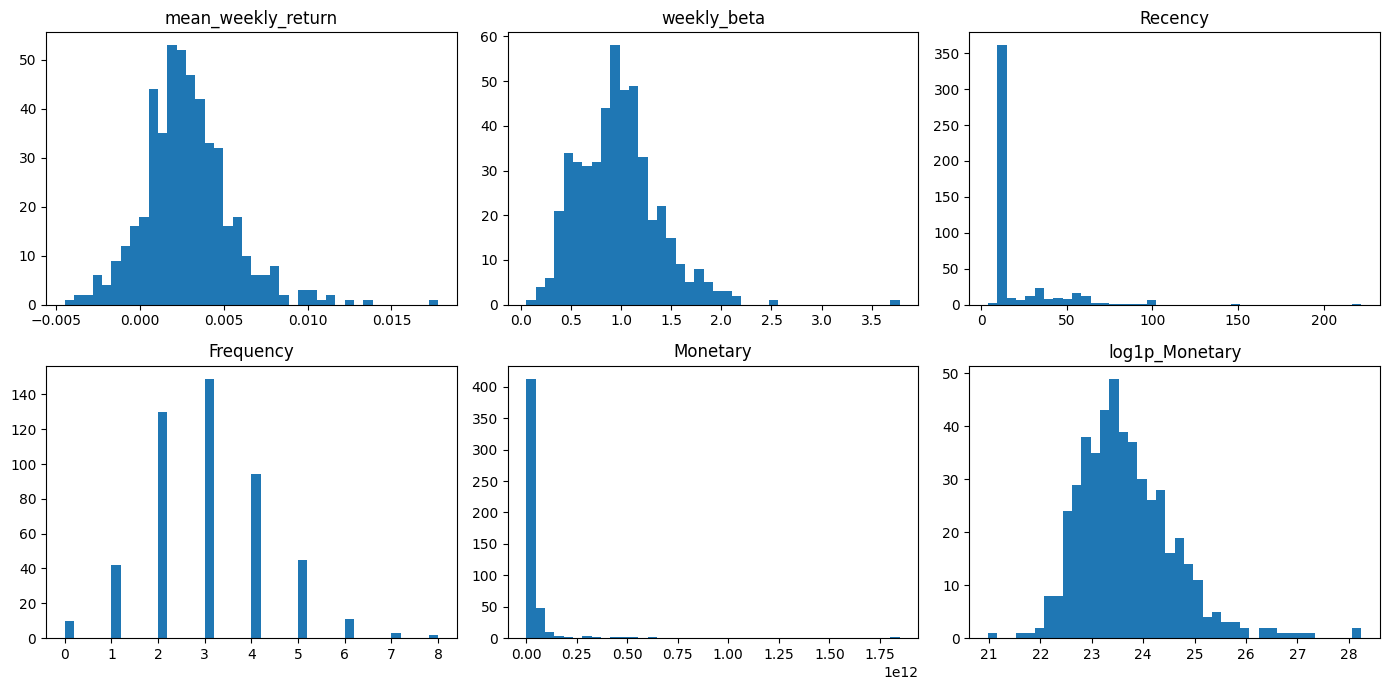

status
excluded     17
included    486
                        mean_weekly_return  weekly_beta  Frequency  log1p_Monetary
GICS Sector                                                                       
Communication Services              0.0029       0.8866        4.0         23.7789
Consumer Discretionary              0.0032       1.1404        3.0         23.8077
Consumer Staples                    0.0010       0.4689        3.0         23.5968
Energy                              0.0057       0.7503        2.0         23.7753
Financials                          0.0033       1.0083        3.0         23.5124
Health Care                         0.0010       0.7591        3.0         23.7200
Industrials                         0.0029       0.9992        3.0         23.4023
Information Technology              0.0038       1.3517        3.0         24.0242
Materials                           0.0017       0.9352        3.0         23.3459
Real Estate                         0.0021      

In [20]:
# 1.5 Final Task 1 feature table: one row per included share
sector = sp500_df.set_index('yf_ticker')[['Security', 'GICS Sector']]
features = sector.join(risk_return, how='inner').join(rfm, how='inner')
features['log1p_Monetary'] = np.log1p(features['Monetary'])
features.to_csv('data/features_task1.csv')
print('Feature table:', features.shape[0], 'shares x', features.shape[1], 'columns -> data/features_task1.csv')

# Summary statistics with skew
cols = ['mean_weekly_return', 'weekly_beta', 'Recency', 'Frequency', 'Monetary', 'log1p_Monetary']
summary = features[cols].describe().T
summary['skew'] = features[cols].skew()
print(summary.round(4).to_string())

# Distributions
fig, axes = plt.subplots(2, 3, figsize=(14, 7))
for ax, col in zip(axes.ravel(), cols):
    ax.hist(features[col], bins=40); ax.set_title(col)
plt.tight_layout(); plt.savefig('data/task1_feature_distributions.png', dpi=150); plt.show()

# Inclusion/exclusion log summary
print(log.groupby('status').size().to_string())
print(features.groupby('GICS Sector')[['mean_weekly_return', 'weekly_beta', 'Frequency', 'log1p_Monetary']].median().round(4).to_string())

### What each metric captures and its limits

Feature definitions and limits as investment signals are discussed in the report.

# Task 2: Stock Segmentation and Sensitivity Analysis
## 2.1 Feature preparation

In [21]:
import seaborn as sns
from scipy.cluster.hierarchy import linkage, dendrogram, cut_tree
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, adjusted_rand_score

data = features.copy()
print("Shares:", len(data))
print("Missing values:", data.isna().sum().sum())

Shares: 486
Missing values: 0


                    count          mean           std           min  \
mean_weekly_return  486.0  2.900000e-03  2.700000e-03 -4.500000e-03   
weekly_beta         486.0  9.737000e-01  4.073000e-01  5.550000e-02   
Recency             486.0  2.040740e+01  2.134240e+01  4.000000e+00   
Frequency           486.0  2.989700e+00  1.330800e+00  0.000000e+00   
Monetary            486.0  3.940419e+10  1.291388e+11  1.297483e+09   
log1p_Monetary      486.0  2.368210e+01  9.422000e-01  2.098370e+01   

                             25%           50%           75%           max  \
mean_weekly_return  1.200000e-03  2.600000e-03  4.200000e-03  1.780000e-02   
weekly_beta         6.666000e-01  9.506000e-01  1.179500e+00  3.778600e+00   
Recency             1.100000e+01  1.100000e+01  1.475000e+01  2.220000e+02   
Frequency           2.000000e+00  3.000000e+00  4.000000e+00  8.000000e+00   
Monetary            1.019517e+10  1.668382e+10  3.227689e+10  1.847697e+12   
log1p_Monetary      2.304520e+01  

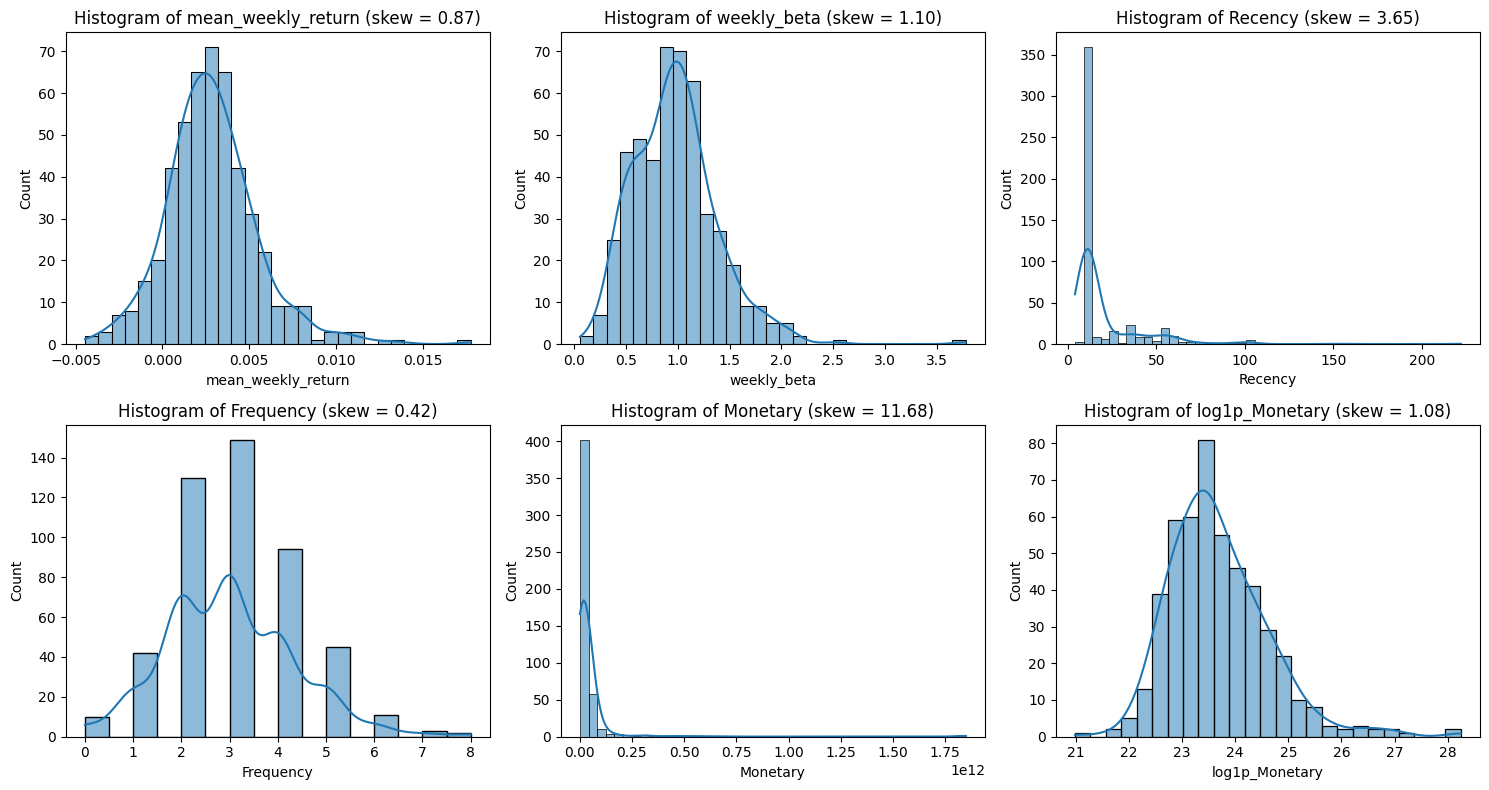

In [22]:
inputs = ["mean_weekly_return", "weekly_beta", "Recency", "Frequency", "Monetary", "log1p_Monetary"]

q1 = data[inputs].quantile(0.25)
q3 = data[inputs].quantile(0.75)
iqr = q3 - q1
outliers = ((data[inputs] < q1 - 1.5 * iqr) | (data[inputs] > q3 + 1.5 * iqr)).sum()

summary = data[inputs].describe().T
summary["Skew"] = data[inputs].skew()
summary["IQR_outliers"] = outliers
print(summary.round(4))

plt.figure(figsize=(15, 8))
for i, col in enumerate(inputs, start=1):
    plt.subplot(2, 3, i)
    sns.histplot(data=data, x=col, kde=True)
    plt.title(f"Histogram of {col} (skew = {data[col].skew():.2f})")
plt.tight_layout()
plt.show()

In [23]:
risk_features = ["mean_weekly_return", "weekly_beta"]
X_risk = data[risk_features].copy()

rfm_features = ["Recency", "Frequency", "Monetary"]
X_rfm = data[rfm_features].copy()
X_rfm["Recency"] = np.log1p(X_rfm["Recency"])
X_rfm["Monetary"] = np.log1p(X_rfm["Monetary"])
X_rfm = X_rfm.rename(columns={"Recency": "log1p_Recency", "Monetary": "log1p_Monetary"})

X_risk_scaled = pd.DataFrame(StandardScaler().fit_transform(X_risk), index=X_risk.index, columns=X_risk.columns)
X_rfm_scaled = pd.DataFrame(StandardScaler().fit_transform(X_rfm), index=X_rfm.index, columns=X_rfm.columns)

print("Skew after transformation:")
print(X_rfm.skew().round(2))
for name, X in [("Risk-return", X_risk_scaled), ("RFM", X_rfm_scaled)]:
    print(f"\n{name} matrix {X.shape}")
    print("Mean:", X.mean().round(2).tolist())
    print("Std: ", X.std(ddof=0).round(2).tolist())
    print("Max |z|:", X.abs().max().round(2).tolist())

Skew after transformation:
log1p_Recency     1.58
Frequency         0.42
log1p_Monetary    1.08
dtype: float64

Risk-return matrix (486, 2)
Mean: [-0.0, 0.0]
Std:  [1.0, 1.0]
Max |z|: [5.63, 6.89]

RFM matrix (486, 3)
Mean: [0.0, -0.0, -0.0]
Std:  [1.0, 1.0, 1.0]
Max |z|: [4.22, 3.77, 4.85]


log1p applied to Monetary and Recency; return, beta and Frequency kept raw; each matrix standardised separately.

## 2.2 Agglomerative clustering (Ward)

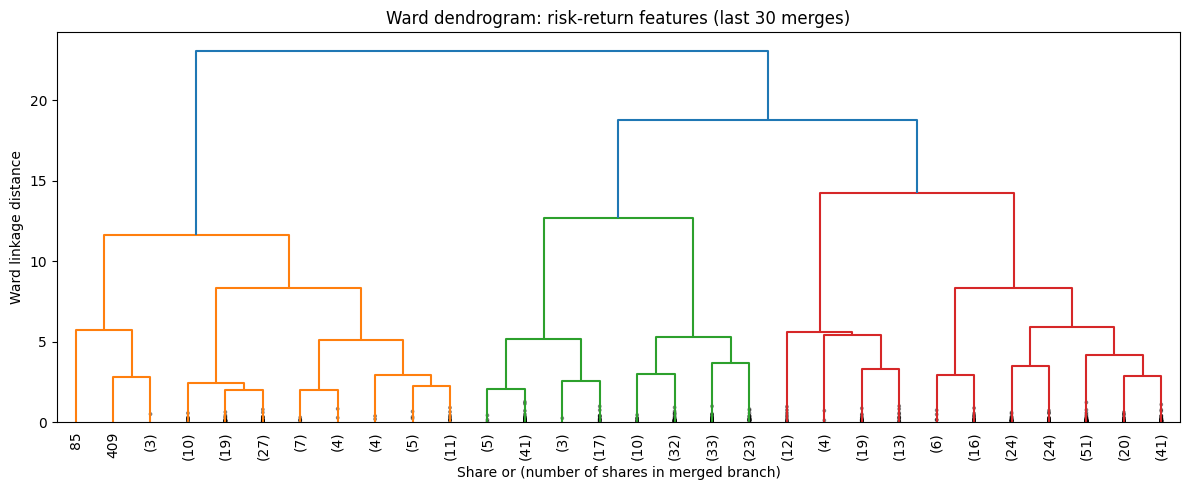

risk-return last 7 merge heights: [23.07 18.8  14.21 12.67 11.6   8.34  8.31]


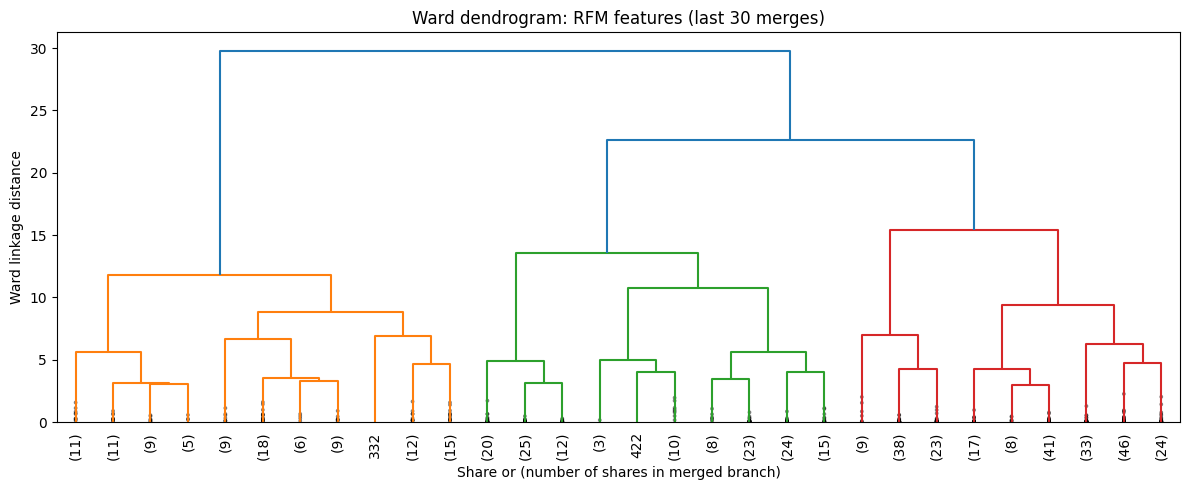

RFM last 7 merge heights: [29.77 22.59 15.42 13.54 11.78 10.76  9.35]


In [24]:
link_risk = linkage(X_risk_scaled, method="ward", metric="euclidean")
link_rfm = linkage(X_rfm_scaled, method="ward", metric="euclidean")

for name, hierarchy in [("risk-return", link_risk), ("RFM", link_rfm)]:
    plt.figure(figsize=(12, 5))
    dendrogram(hierarchy, truncate_mode="lastp", p=30, leaf_rotation=90, show_contracted=True)
    plt.title(f"Ward dendrogram: {name} features (last 30 merges)")
    plt.xlabel("Share or (number of shares in merged branch)")
    plt.ylabel("Ward linkage distance")
    plt.tight_layout()
    plt.savefig(f"data/dendrogram_{name.replace('-', '_')}.png", dpi=150)
    plt.show()

    print(name, "last 7 merge heights:", np.round(hierarchy[-7:, 2][::-1], 2))

     Matrix  k  Silhouette  Smallest                             Sizes
Risk-return  2       0.339        92                         [394, 92]
Risk-return  3       0.274        92                    [230, 164, 92]
Risk-return  4       0.282        48                [182, 164, 92, 48]
Risk-return  5       0.304        48             [182, 98, 92, 66, 48]
Risk-return  6       0.320         5          [182, 98, 87, 66, 48, 5]
Risk-return  7       0.324         5      [160, 98, 87, 66, 48, 22, 5]
Risk-return  8       0.321         5  [160, 98, 66, 56, 48, 31, 22, 5]
        RFM  2       0.402       106                        [380, 106]
        RFM  3       0.335       106                   [239, 141, 106]
        RFM  4       0.293        70               [169, 141, 106, 70]
        RFM  5       0.286        57            [169, 106, 84, 70, 57]
        RFM  6       0.276        36         [169, 84, 70, 70, 57, 36]
        RFM  7       0.297        14     [169, 70, 70, 70, 57, 36, 14]
      

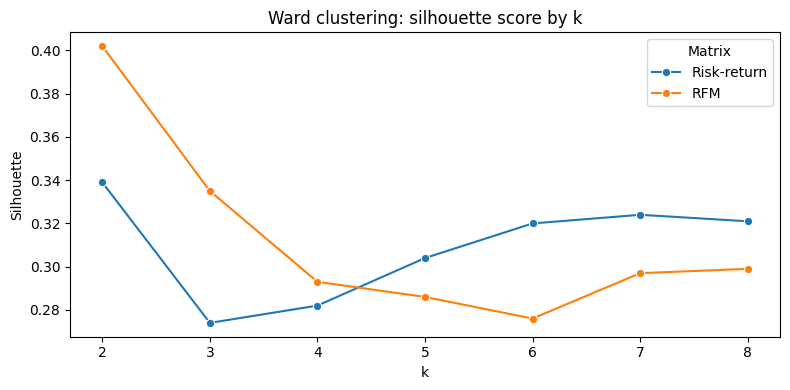

In [25]:
ward_results = []
for name, X, hierarchy in [("Risk-return", X_risk_scaled, link_risk), ("RFM", X_rfm_scaled, link_rfm)]:
    for k in range(2, 9):
        labels = cut_tree(hierarchy, n_clusters=k).ravel() + 1
        sizes = sorted(np.bincount(labels)[1:], reverse=True)
        ward_results.append({
            "Matrix": name,
            "k": k,
            "Silhouette": round(silhouette_score(X, labels), 3),
            "Smallest": min(sizes),
            "Sizes": sizes
        })

ward_results = pd.DataFrame(ward_results)
print(ward_results.to_string(index=False))

plt.figure(figsize=(8, 4))
sns.lineplot(data=ward_results, x="k", y="Silhouette", hue="Matrix", marker="o")
plt.title("Ward clustering: silhouette score by k")
plt.tight_layout()
plt.savefig("data/ward_silhouette.png", dpi=150)
plt.show()

In [26]:
profile_cols = ["mean_weekly_return", "weekly_beta", "Recency", "Frequency", "Monetary"]

for name, hierarchy, ks in [("Risk-return", link_risk, [2, 3, 5]), ("RFM", link_rfm, [2, 3])]:
    for k in ks:
        labels = cut_tree(hierarchy, n_clusters=k).ravel() + 1
        profile = data.assign(Cluster=labels).groupby("Cluster").agg(
            Shares=("Security", "count"),
            Return=("mean_weekly_return", "mean"),
            Beta=("weekly_beta", "mean"),
            Recency_median=("Recency", "median"),
            Frequency=("Frequency", "mean"),
            Monetary_median_bn=("Monetary", lambda m: m.median() / 1e9),
        )
        print(f"\n{name} Ward, k = {k}")
        print(profile.round(4))


Risk-return Ward, k = 2
         Shares  Return    Beta  Recency_median  Frequency  Monetary_median_bn
Cluster                                                                       
1           394  0.0020  0.8979            11.0     2.9416             15.3252
2            92  0.0063  1.2981            11.0     3.1957             24.1841

Risk-return Ward, k = 3
         Shares  Return    Beta  Recency_median  Frequency  Monetary_median_bn
Cluster                                                                       
1           230  0.0015  1.1096            11.0     3.0565             14.1114
2           164  0.0029  0.6012            11.0     2.7805             17.6494
3            92  0.0063  1.2981            11.0     3.1957             24.1841

Risk-return Ward, k = 5
         Shares  Return    Beta  Recency_median  Frequency  Monetary_median_bn
Cluster                                                                       
1           182  0.0013  0.9728            11.0     3.01

In [27]:
K_RISK, K_RFM = 5, 3
data["Ward_Risk"] = cut_tree(link_risk, n_clusters=K_RISK).ravel() + 1
data["Ward_RFM"] = cut_tree(link_rfm, n_clusters=K_RFM).ravel() + 1
print(data["Ward_Risk"].value_counts().sort_index())
print(data["Ward_RFM"].value_counts().sort_index())

Ward_Risk
1    182
2     66
3     98
4     48
5     92
Name: count, dtype: int64
Ward_RFM
1    141
2    239
3    106
Name: count, dtype: int64


Selected Ward k: risk-return 5, RFM 3 (silhouette, sizes and profiles).

## 2.3 K-means clustering

     Matrix  k  Silhouette  Inertia  Smallest                             Sizes
Risk-return  2       0.387    621.6       143                        [343, 143]
Risk-return  3       0.329    461.2       119                   [202, 165, 119]
Risk-return  4       0.327    371.6        40               [160, 154, 132, 40]
Risk-return  5       0.341    309.6        27           [166, 131, 112, 50, 27]
Risk-return  6       0.334    265.4         5        [158, 113, 111, 56, 43, 5]
Risk-return  7       0.331    227.5         5      [143, 85, 83, 74, 48, 48, 5]
Risk-return  8       0.354    194.4         5  [136, 79, 78, 76, 43, 40, 29, 5]
        RFM  2       0.415    999.5       102                        [384, 102]
        RFM  3       0.343    742.5        90                    [257, 139, 90]
        RFM  4       0.362    559.2        82                [194, 120, 90, 82]
        RFM  5       0.348    480.7        40            [141, 119, 99, 87, 40]
        RFM  6       0.345    421.2     

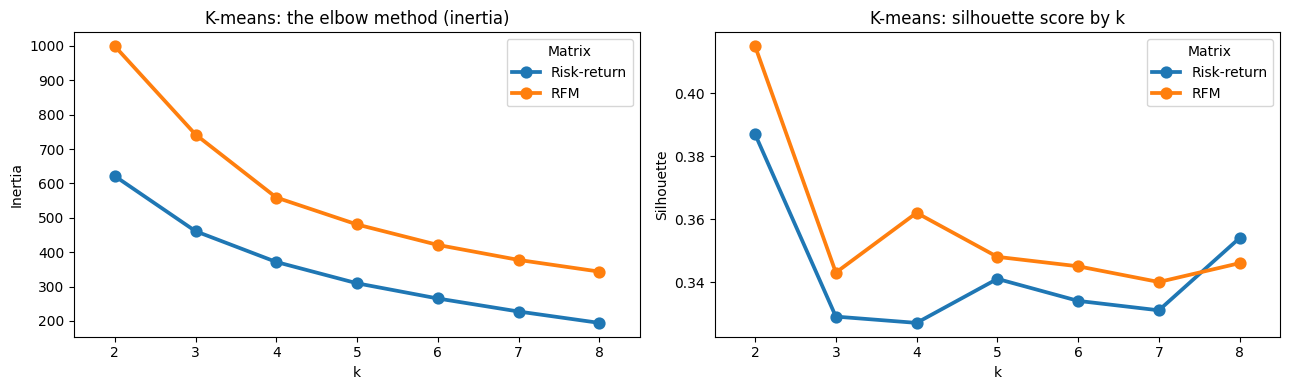

In [28]:
SEED = 42
kmeans_results = []
for name, X in [("Risk-return", X_risk_scaled), ("RFM", X_rfm_scaled)]:
    for k in range(2, 9):
        model = KMeans(n_clusters=k, random_state=SEED, n_init=20)
        labels = model.fit_predict(X)
        sizes = sorted(np.bincount(labels), reverse=True)
        kmeans_results.append({
            "Matrix": name,
            "k": k,
            "Silhouette": round(silhouette_score(X, labels), 3),
            "Inertia": round(model.inertia_, 1),
            "Smallest": min(sizes),
            "Sizes": sizes
        })

kmeans_results = pd.DataFrame(kmeans_results)
print(kmeans_results.to_string(index=False))

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.pointplot(data=kmeans_results, x="k", y="Inertia", hue="Matrix", ax=axes[0])
axes[0].set_title("K-means: the elbow method (inertia)")
sns.pointplot(data=kmeans_results, x="k", y="Silhouette", hue="Matrix", ax=axes[1])
axes[1].set_title("K-means: silhouette score by k")
plt.tight_layout()
plt.savefig("data/kmeans_elbow_silhouette.png", dpi=150)
plt.show()

In [29]:
for name, X, ks in [("Risk-return", X_risk_scaled, [5]), ("RFM", X_rfm_scaled, [3, 4])]:
    for k in ks:
        labels = KMeans(n_clusters=k, random_state=SEED, n_init=20).fit_predict(X) + 1
        profile = data.assign(Cluster=labels).groupby("Cluster").agg(
            Shares=("Security", "count"),
            Return=("mean_weekly_return", "mean"),
            Beta=("weekly_beta", "mean"),
            Recency_median=("Recency", "median"),
            Frequency=("Frequency", "mean"),
            Monetary_median_bn=("Monetary", lambda m: m.median() / 1e9),
        )
        print(f"\n{name} K-means, k = {k}")
        print(profile.round(4))


Risk-return K-means, k = 5
         Shares  Return    Beta  Recency_median  Frequency  Monetary_median_bn
Cluster                                                                       
1           112  0.0003  1.0200            11.0     3.0179             13.5030
2           166  0.0043  0.9964            11.0     2.8916             17.7198
3           131  0.0021  0.5335            11.0     2.9771             15.0439
4            27  0.0093  1.5595            11.0     3.2222             28.2106
5            50  0.0024  1.6315            11.0     3.1600             32.1482

RFM K-means, k = 3
         Shares  Return    Beta  Recency_median  Frequency  Monetary_median_bn
Cluster                                                                       
1           257  0.0025  0.9337            11.0     3.3696             11.2016
2           139  0.0034  1.0141            11.0     2.8993             42.8916
3            90  0.0030  1.0254            53.5     2.0444             21.1834

RFM

In [30]:
KM_RISK, KM_RFM = 5, 4
data["KM_Risk"] = KMeans(n_clusters=KM_RISK, random_state=SEED, n_init=20).fit_predict(X_risk_scaled) + 1
data["KM_RFM"] = KMeans(n_clusters=KM_RFM, random_state=SEED, n_init=20).fit_predict(X_rfm_scaled) + 1
print(data["KM_Risk"].value_counts().sort_index())
print(data["KM_RFM"].value_counts().sort_index())

KM_Risk
1    112
2    166
3    131
4     27
5     50
Name: count, dtype: int64
KM_RFM
1     82
2    194
3     90
4    120
Name: count, dtype: int64


Selected K-means k: risk-return 5, RFM 4 (silhouette, inertia and sizes).

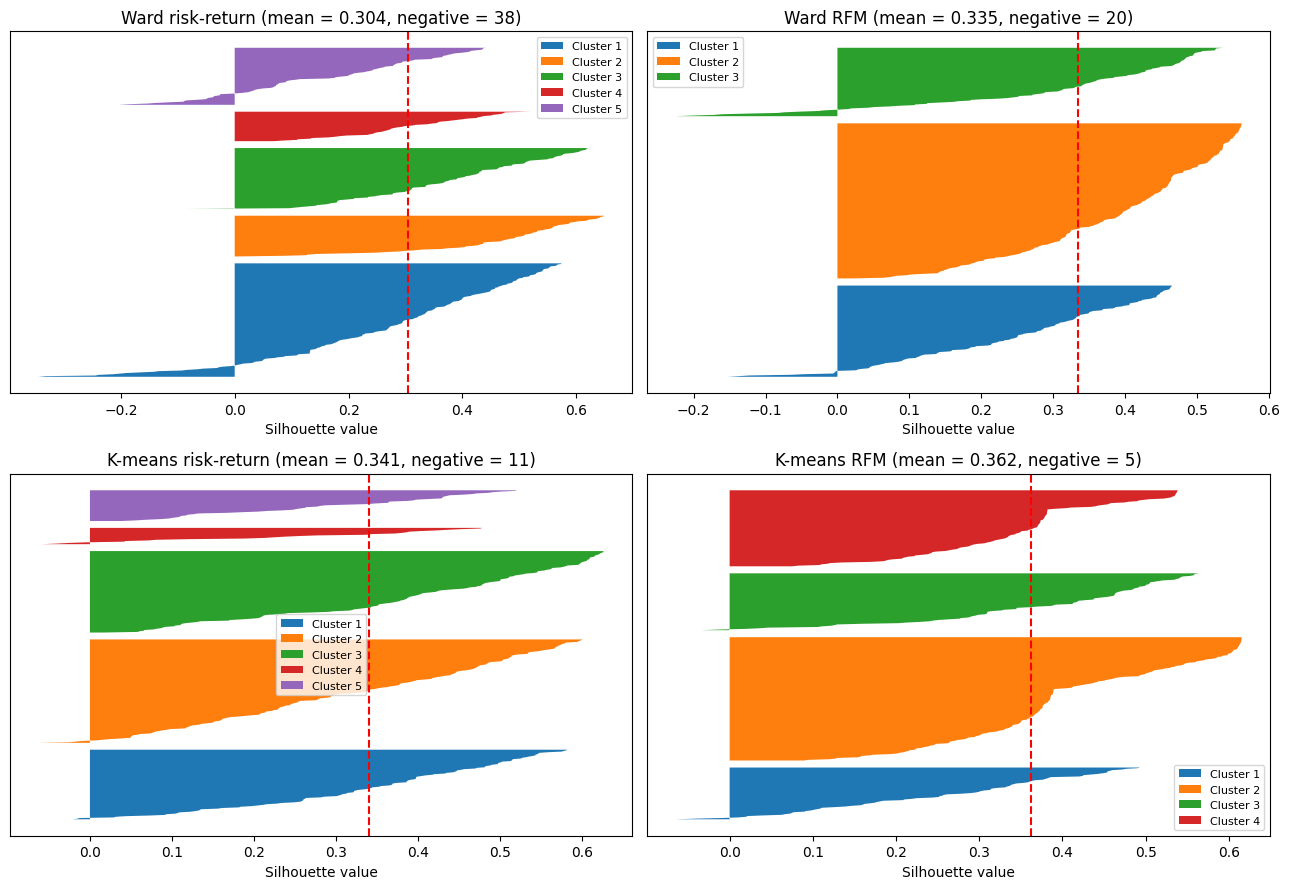

In [31]:
from sklearn.metrics import silhouette_samples

fig, axes = plt.subplots(2, 2, figsize=(13, 9))
solutions = [("Ward risk-return", X_risk_scaled, "Ward_Risk"), ("Ward RFM", X_rfm_scaled, "Ward_RFM"),
             ("K-means risk-return", X_risk_scaled, "KM_Risk"), ("K-means RFM", X_rfm_scaled, "KM_RFM")]
for ax, (title, X, col) in zip(axes.flat, solutions):
    s = silhouette_samples(X, data[col])
    y = 0
    for c in sorted(data[col].unique()):
        vals = np.sort(s[data[col] == c])
        ax.fill_betweenx(np.arange(y, y + len(vals)), 0, vals, label=f"Cluster {c}")
        y += len(vals) + 10
    ax.axvline(s.mean(), color="red", linestyle="--")
    ax.set_title(f"{title} (mean = {s.mean():.3f}, negative = {(s < 0).sum()})")
    ax.set_xlabel("Silhouette value")
    ax.set_yticks([])
    ax.legend(fontsize=8)
plt.tight_layout()
plt.savefig("data/silhouette_plots.png", dpi=150)
plt.show()

No cluster is mostly negative in any selected solution.

## 2.4 Cluster profiles and algorithm comparison

In [32]:
for col in ["Ward_Risk", "KM_Risk", "Ward_RFM", "KM_RFM"]:
    profile = data.groupby(col).agg(
        Shares=("Security", "count"),
        Return_pct=("mean_weekly_return", lambda r: r.mean() * 100),
        Beta=("weekly_beta", "mean"),
        Recency_median=("Recency", "median"),
        Frequency=("Frequency", "mean"),
        Monetary_median_bn=("Monetary", lambda m: m.median() / 1e9),
        Top_sector=("GICS Sector", lambda s: s.value_counts().index[0]),
    )
    print(f"\n{col}")
    print(profile.round(3).to_string())

data.to_csv("data/cluster_assignments.csv")


Ward_Risk
           Shares  Return_pct   Beta  Recency_median  Frequency  Monetary_median_bn              Top_sector
Ward_Risk                                                                                                  
1             182       0.132  0.973            11.0      3.011              12.985             Industrials
2              66       0.088  0.439            11.0      2.894              17.701        Consumer Staples
3              98       0.422  0.710            11.0      2.704              17.649              Financials
4              48       0.200  1.628            11.0      3.229              28.698  Information Technology
5              92       0.632  1.298            11.0      3.196              24.184  Information Technology

KM_Risk
         Shares  Return_pct   Beta  Recency_median  Frequency  Monetary_median_bn              Top_sector
KM_Risk                                                                                                  
1           

PCA explained variance: [0.436 0.336] total: 0.772
     log1p_Recency  Frequency  log1p_Monetary
PC1          0.712     -0.649           0.266
PC2          0.027      0.405           0.914


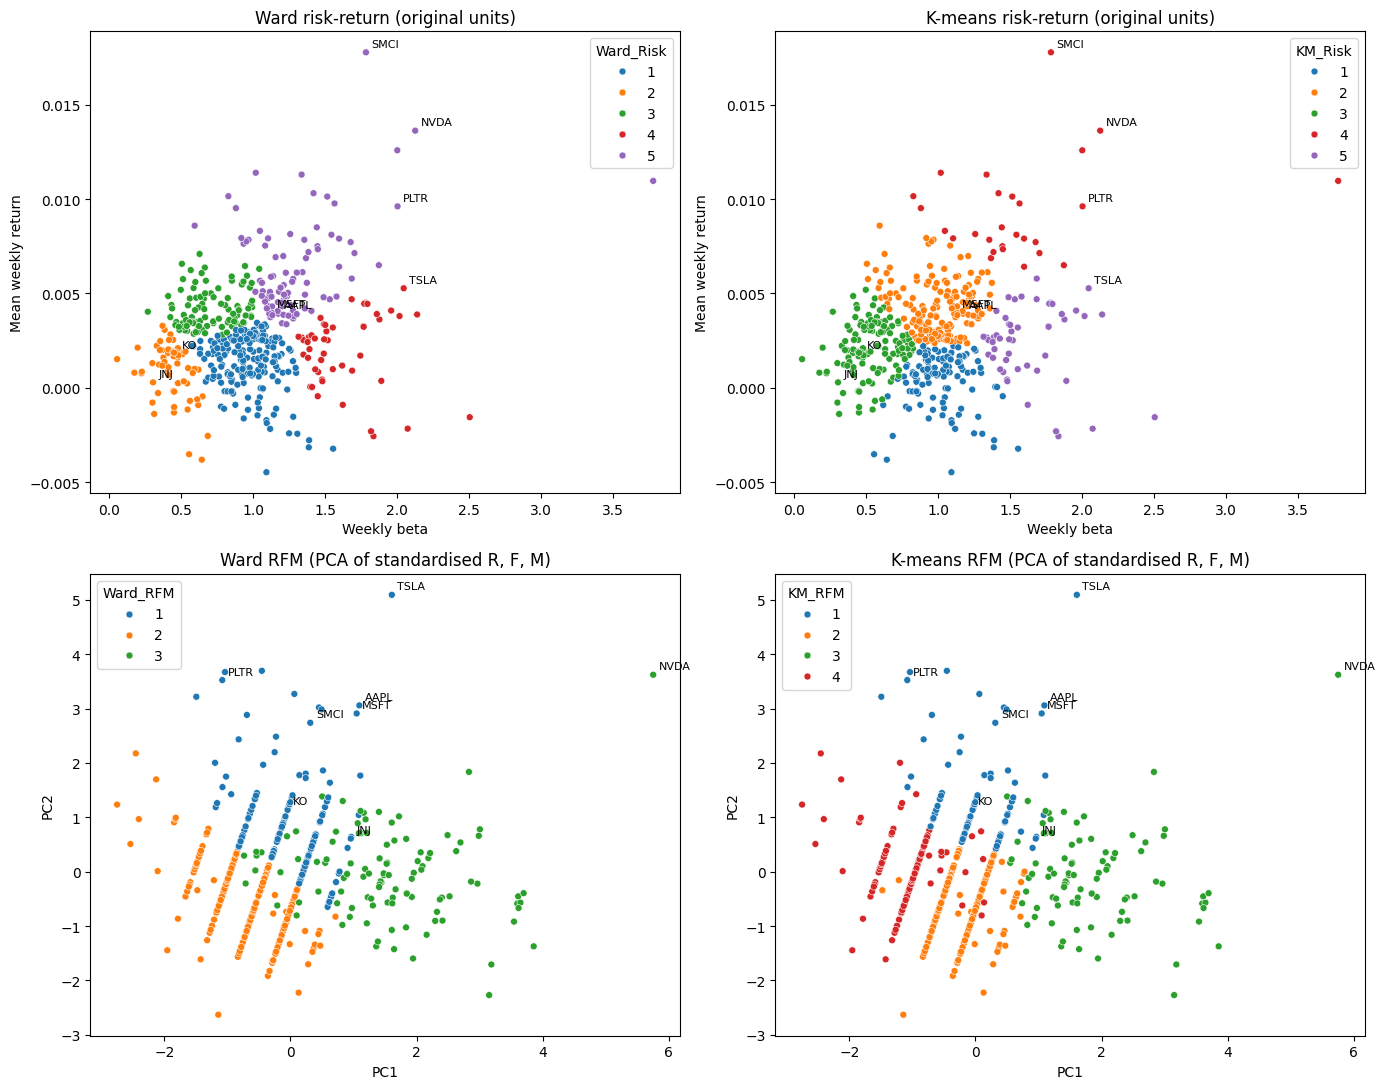

In [33]:
from sklearn.decomposition import PCA

pca = PCA(n_components=2, random_state=SEED)
rfm_2d = pca.fit_transform(X_rfm_scaled)
data["PC1"], data["PC2"] = rfm_2d[:, 0], rfm_2d[:, 1]
print("PCA explained variance:", pca.explained_variance_ratio_.round(3), "total:", pca.explained_variance_ratio_.sum().round(3))
print(pd.DataFrame(pca.components_, columns=X_rfm.columns, index=["PC1", "PC2"]).round(3))

label_shares = ["NVDA", "AAPL", "MSFT", "TSLA", "SMCI", "PLTR", "KO", "JNJ"]
fig, axes = plt.subplots(2, 2, figsize=(14, 11))
plots = [("Ward_Risk", "weekly_beta", "mean_weekly_return", "Ward risk-return (original units)"),
         ("KM_Risk", "weekly_beta", "mean_weekly_return", "K-means risk-return (original units)"),
         ("Ward_RFM", "PC1", "PC2", "Ward RFM (PCA of standardised R, F, M)"),
         ("KM_RFM", "PC1", "PC2", "K-means RFM (PCA of standardised R, F, M)")]
for ax, (col, x, y, title) in zip(axes.flat, plots):
    sns.scatterplot(data=data, x=x, y=y, hue=col, palette="tab10", ax=ax, s=25)
    for t in label_shares:
        if t in data.index:
            ax.annotate(t, (data.loc[t, x], data.loc[t, y]), xytext=(4, 4), textcoords="offset points", fontsize=8)
    ax.set_title(title)
axes[0, 0].set_xlabel("Weekly beta"); axes[0, 0].set_ylabel("Mean weekly return")
axes[0, 1].set_xlabel("Weekly beta"); axes[0, 1].set_ylabel("Mean weekly return")
plt.tight_layout()
plt.savefig("data/cluster_scatter_2d.png", dpi=150)
plt.show()

Risk-return plotted in original units; RFM shown via PCA (77.2% of variance).

In [34]:
print("Risk-return: Ward (rows) vs K-means (columns)")
print(pd.crosstab(data["Ward_Risk"], data["KM_Risk"]))
print("ARI:", round(adjusted_rand_score(data["Ward_Risk"], data["KM_Risk"]), 3))

print("\nRFM: Ward k=3 (rows) vs K-means k=4 (columns)")
print(pd.crosstab(data["Ward_RFM"], data["KM_RFM"]))
print("ARI:", round(adjusted_rand_score(data["Ward_RFM"], data["KM_RFM"]), 3))

km_rfm_3 = KMeans(n_clusters=3, random_state=SEED, n_init=20).fit_predict(X_rfm_scaled) + 1
print("\nRFM at equal k = 3: Ward (rows) vs K-means (columns)")
print(pd.crosstab(data["Ward_RFM"], km_rfm_3))
print("ARI:", round(adjusted_rand_score(data["Ward_RFM"], km_rfm_3), 3))

Risk-return: Ward (rows) vs K-means (columns)
KM_Risk      1   2   3   4   5
Ward_Risk                     
1          104  49  29   0   0
2            5   0  61   0   0
3            0  57  41   0   0
4            3   0   0   0  45
5            0  60   0  27   5
ARI: 0.318

RFM: Ward k=3 (rows) vs K-means k=4 (columns)
KM_RFM     1    2   3   4
Ward_RFM                 
1         81   46   0  14
2          0  146   0  93
3          1    2  90  13
ARI: 0.419

RFM at equal k = 3: Ward (rows) vs K-means (columns)
col_0       1    2   3
Ward_RFM              
1           5  136   0
2         239    0   0
3          13    3  90
ARI: 0.876


Ward vs K-means ARI: risk-return 0.318, RFM 0.419 (0.876 at equal k = 3).

In [35]:
for name, X, k, col in [("Risk-return", X_risk_scaled, KM_RISK, "KM_Risk"), ("RFM", X_rfm_scaled, KM_RFM, "KM_RFM")]:
    aris = [adjusted_rand_score(data[col], KMeans(n_clusters=k, random_state=s, n_init=20).fit_predict(X)) for s in range(5)]
    print(f"K-means {name}: ARI vs seed 42 for seeds 0-4 =", np.round(aris, 3))

print("\nRisk-return vs RFM memberships (Ward):", round(adjusted_rand_score(data["Ward_Risk"], data["Ward_RFM"]), 3))
print("Risk-return vs RFM memberships (K-means):", round(adjusted_rand_score(data["KM_Risk"], data["KM_RFM"]), 3))

K-means Risk-return: ARI vs seed 42 for seeds 0-4 = [0.93  0.91  0.915 0.874 0.93 ]
K-means RFM: ARI vs seed 42 for seeds 0-4 = [1. 1. 1. 1. 1.]

Risk-return vs RFM memberships (Ward): 0.048
Risk-return vs RFM memberships (K-means): 0.014


## 2.5 RFM sensitivity and correlated inputs

### 2.5.1 Correlation analysis

Pearson correlations:
                Recency  log1p_Recency  Frequency  log1p_Monetary
Recency           1.000          0.930     -0.346           0.152
log1p_Recency     0.930          1.000     -0.285           0.127
Frequency        -0.346         -0.285      1.000           0.013
log1p_Monetary    0.152          0.127      0.013           1.000

Spearman (rank) correlations:
                Recency  log1p_Recency  Frequency  log1p_Monetary
Recency           1.000          1.000     -0.196           0.137
log1p_Recency     1.000          1.000     -0.196           0.137
Frequency        -0.196         -0.196      1.000          -0.048
log1p_Monetary    0.137          0.137     -0.048           1.000


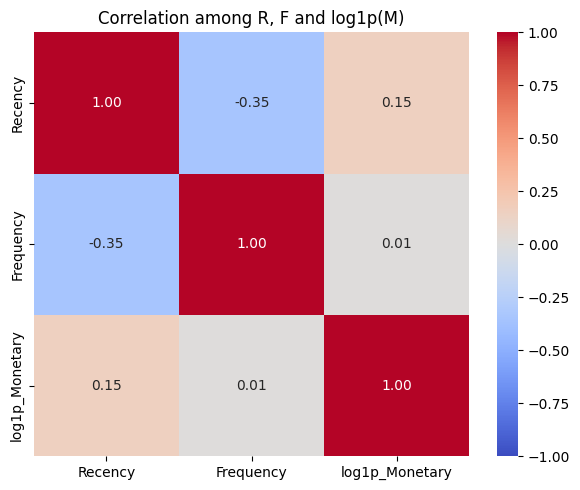

In [36]:
corr_inputs = pd.DataFrame({
    "Recency": data["Recency"],
    "log1p_Recency": np.log1p(data["Recency"]),
    "Frequency": data["Frequency"],
    "log1p_Monetary": np.log1p(data["Monetary"]),
})

print("Pearson correlations:")
print(corr_inputs.corr().round(3))
print("\nSpearman (rank) correlations:")
print(corr_inputs.corr(method="spearman").round(3))

plt.figure(figsize=(6, 5))
sns.heatmap(corr_inputs[["Recency", "Frequency", "log1p_Monetary"]].corr(), annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Correlation among R, F and log1p(M)")
plt.tight_layout()
plt.savefig("data/rfm_correlation.png", dpi=150)
plt.show()

R–F −0.35, R–log1p(M) 0.15, F–log1p(M) 0.01.

### 2.5.2 Removal of Monetary

In [37]:
X_rf = X_rfm[["log1p_Recency", "Frequency"]].copy()
X_rf_scaled = pd.DataFrame(StandardScaler().fit_transform(X_rf), index=X_rf.index, columns=X_rf.columns)

link_rf = linkage(X_rf_scaled, method="ward", metric="euclidean")
data["Ward_RF"] = cut_tree(link_rf, n_clusters=K_RFM).ravel() + 1

print("Shares:", len(X_rf_scaled), "| k =", K_RFM)
print("Silhouette (R, F only):", round(silhouette_score(X_rf_scaled, data["Ward_RF"]), 3))
print("\nWard RFM (rows) vs Ward RF (columns)")
print(pd.crosstab(data["Ward_RFM"], data["Ward_RF"]))
print("ARI:", round(adjusted_rand_score(data["Ward_RFM"], data["Ward_RF"]), 3))

for col in ["Ward_RFM", "Ward_RF"]:
    profile = data.groupby(col).agg(
        Shares=("Security", "count"),
        Recency_median=("Recency", "median"),
        Frequency=("Frequency", "mean"),
        Monetary_median_bn=("Monetary", lambda m: m.median() / 1e9),
        Monetary_mean_bn=("Monetary", lambda m: m.mean() / 1e9),
    )
    print(f"\n{col} traded value profile")
    print(profile.round(2).to_string())

data.to_csv("data/cluster_assignments.csv")

Shares: 486 | k = 3
Silhouette (R, F only): 0.508

Ward RFM (rows) vs Ward RF (columns)
Ward_RF     1   2    3
Ward_RFM              
1          74  59    8
2         173  66    0
3           5   0  101
ARI: 0.349

Ward_RFM traded value profile
          Shares  Recency_median  Frequency  Monetary_median_bn  Monetary_mean_bn
Ward_RFM                                                                         
1            141            11.0       2.94               42.01             84.42
2            239            11.0       3.28               11.15             11.68
3            106            46.5       2.40               19.49             42.04

Ward_RF traded value profile
         Shares  Recency_median  Frequency  Monetary_median_bn  Monetary_mean_bn
Ward_RF                                                                         
1           252            11.0       3.78               14.74             30.01
2           125            11.0       1.80               17.70          

Removing M: ARI 0.349 with the R, F, M solution; traded value no longer separates clusters.

### Data snapshot inventory and fingerprints

In [38]:
# SHA-256 hash of each data snapshot file, stored in acquisition_log.json for provenance
import hashlib
fingerprints = {f: hashlib.sha256(open('data/' + f, 'rb').read()).hexdigest()
                for f in sorted(os.listdir('data')) if not f.endswith('.json')}
acquisition_log['sha256'] = fingerprints
json.dump(acquisition_log, open('data/acquisition_log.json', 'w'), indent=2)
for f, h in fingerprints.items():
    print(f'{f:40s} {h[:16]}...')

cluster_assignments.csv                  b5c85b3c51690416...
cluster_scatter_2d.png                   51277b7507b0c9fc...
dendrogram_RFM.png                       e8ca0ef55a31d6a6...
dendrogram_risk_return.png               2e7ebe0a5518134c...
features_task1.csv                       f4d489204beab81c...
gspc_daily_raw_2021_2024.csv             b25b2ac034e56b5d...
inclusion_exclusion_log.csv              9fd8d439024da7cc...
kmeans_elbow_silhouette.png              ec99dd543bf2b192...
rfm_correlation.png                      7123250f576c9b52...
rfm_features.csv                         aa0d9be419658292...
risk_return_features.csv                 8453950465dade45...
silhouette_plots.png                     176c8ce7d436b625...
sp500_constituents.csv                   61a6c44a1a293d26...
sp500_daily_raw_2021_2024.csv.gz         61657387e96b9ba7...
task1_feature_distributions.png          683ba8d25a27d729...
ward_silhouette.png                      83e6aef3e7245c09...


In [39]:
# Inventory of the preserved data snapshot
for f in sorted(os.listdir('data')):
    print(f'{f:40s} {os.path.getsize("data/" + f) / 1e6:6.2f} MB')

acquisition_log.json                       0.00 MB
cluster_assignments.csv                    0.09 MB
cluster_scatter_2d.png                     0.40 MB
dendrogram_RFM.png                         0.06 MB
dendrogram_risk_return.png                 0.06 MB
features_task1.csv                         0.06 MB
gspc_daily_raw_2021_2024.csv               0.10 MB
inclusion_exclusion_log.csv                0.04 MB
kmeans_elbow_silhouette.png                0.10 MB
rfm_correlation.png                        0.05 MB
rfm_features.csv                           0.02 MB
risk_return_features.csv                   0.02 MB
silhouette_plots.png                       0.13 MB
sp500_constituents.csv                     0.07 MB
sp500_daily_raw_2021_2024.csv.gz          14.00 MB
task1_feature_distributions.png            0.09 MB
ward_silhouette.png                        0.06 MB


## Appendix: reload saved snapshot

Use this instead of the 1.1 download cells to reproduce the submitted results from the files in `data/`.


In [40]:
# Reload the preserved dataset instead of downloading again (run after the setup cell, then continue from 1.2)
sp500_df = pd.read_csv('data/sp500_constituents.csv')
tickers = sp500_df['yf_ticker'].tolist()
url = 'https://en.wikipedia.org/wiki/List_of_S%26P_500_companies'
acquisition_log = json.load(open('data/acquisition_log.json'))
retrieval_date, no_data = acquisition_log['ticker_retrieved'], acquisition_log['tickers_no_data']

raw = pd.read_csv('data/sp500_daily_raw_2021_2024.csv.gz', header=[0, 1], index_col=0, parse_dates=True)
adj_close, close, volume = raw['Adj Close'], raw['Close'], raw['Volume']
actions = raw[['Dividends', 'Stock Splits']]
bench_raw = pd.read_csv('data/gspc_daily_raw_2021_2024.csv', header=[0, 1], index_col=0, parse_dates=True)
bench_adj = bench_raw['Adj Close'].squeeze()
print('Reloaded', len(tickers), 'tickers | retrieved', retrieval_date, '| days', len(adj_close))

Reloaded 503 tickers | retrieved 2026-11-22 20:18 UTC | days 1005
